# 選定プレフィックスごとのフロー長分布

`flow length = packet_count`（双方向5タプルあたりパケット数）を、**Raw／Broad removed／Broad retained**で比較します。成功済みrunのCSVのみを読み、PCAP・Aguri・Scan判定を再実行しません。**このローカルMacには実データがありません。研究室PCへのSSH接続・転送も行いません。**

既存の `02_main_prefix_comparison.ipynb` と `03_prefix_deep_dive.ipynb` の所属・除外定義に合わせます。大会時の保存出力は native選定18個、所属550,289行、一意549,990フローです。これは過去の記録であり、今回の入力から再現した結果ではありません。18個を固定リストにせず、指定runの台帳と照合します。

最初に設定・manifest・選定台帳を表示します。全CSVの検査が成功するまで図を作りません。診断で停止した場合は後続セルを実行せず、設定を修正して **Kernelを再起動してRun All** してください。デモは明示指定のみです。詳細は `docs/guide/prefix-flow-length-histograms.md` を参照してください。


## 1. 入力と実行モード

`MAWI_ANALYSIS_ROOT` はコードと別のデータ保管rootでも指定できます。manifestの相対パスはそのroot基準、絶対パスは記録どおりに扱い、別ファイルを探索して代用しません。

研究室PCでの想定入口は `results/202604081400/scan_source_driven_removal/run_manifest.json`。その中の `flows`（旧互換名 `flows_csv`）、`flow_labels`、`prefixes`、`flow_prefix_membership` とflow cache manifestを確認してください。時間窓集計や送信元要約だけではこの分布は復元できません。

デモを試す場合だけ `DEMO = True` または `MAWI_FLOW_LENGTH_DEMO=1` にします。下の初期値では実データモードです。実データモードのdataset/runは明示指定が必要です。


In [2]:
from pathlib import Path
import os
import sys
import tempfile
import json
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Notebookをこのrepoのrootまたはnotebooks/から開いてください。
CODE_ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
                  if (p / 'src/mawi_global_analysis/flow_length.py').is_file()), None)
if CODE_ROOT is None:
    raise RuntimeError('このNotebookが含まれるリポジトリから開いてください')
sys.path.insert(0, str(CODE_ROOT / 'src'))
from mawi_global_analysis.flow_length import inspect_run, analyze_run, make_demo_run

DEMO = os.environ.get('MAWI_FLOW_LENGTH_DEMO', '0') == '1'
DATA_ROOT = Path(os.environ.get('MAWI_ANALYSIS_ROOT', '/home/s-sakai/mawi-global-analysis')).expanduser().resolve()
DATASET_ID = os.environ.get('MAWI_DATASET_ID', '202604081400')
RUN_NAME = os.environ.get('MAWI_RUN_NAME', 'scan_source_driven_removal')
CHUNK_SIZE = int(os.environ.get('MAWI_FLOW_LENGTH_CHUNK_SIZE', '100000'))
SCRATCH_DIR = os.environ.get('MAWI_FLOW_LENGTH_SCRATCH_DIR') or None
OUTPUT_DIR = os.environ.get('MAWI_FLOW_LENGTH_OUTPUT_DIR') or None  # 保存する場合は存在しない新規フォルダ
PREFIXES_PER_PAGE = 3
COUNT_LOG = True  # symlog: 0を残し、1より大きい度数を対数表示

# 再実行時に古い結果が残らないよう、入力検査前に破棄する。
result = None
_result_context = None

def input_context():
    return (str(DATA_ROOT), DATASET_ID, RUN_NAME, DEMO)

def require_result():
    if result is None or _result_context != input_context():
        raise RuntimeError('入力が変わったか集計に失敗しています。結果を使う前に入力検査・集計セルを再実行してください。')
if DEMO:
    demo_workspace = tempfile.TemporaryDirectory(prefix='mawi-flow-length-demo-')
    DATA_ROOT = Path(demo_workspace.name)
    DATASET_ID, RUN_NAME = make_demo_run(DATA_ROOT)
    evidence_label = 'SYNTHETIC DEMO — 実MAWIデータではありません'
else:
    if not DATASET_ID or not RUN_NAME:
        raise RuntimeError('MAWI_DATASET_ID と MAWI_RUN_NAME、または上のパラメータを明示指定してください。'
                           'このMacに実データはありません。デモはDEMO=Trueでのみ有効です。')
    evidence_label = '保存済みrun成果物の解析 — PCAP再処理なし'
print(evidence_label)
print(f'data root: {DATA_ROOT}\ndataset: {DATASET_ID}\nrun: {RUN_NAME}')

# 正確な整数度数を保存して次回のCSV全行読込を省く。既存run成果物は上書きしない。
EXACT_CACHE_DIR = Path(os.environ.get('MAWI_FLOW_LENGTH_EXACT_CACHE_DIR',
    str(DATA_ROOT / 'results' / 'flow_length_exact_cache' / DATASET_ID / RUN_NAME))).expanduser().resolve()


保存済みrun成果物の解析 — PCAP再処理なし
data root: /home/s-sakai/mawi-global-analysis
dataset: 202604081400
run: scan_source_driven_removal


## 2. 設定・参照先・選定数の事前検査

成功状態、dataset、保存設定のSHA-256と現行 `scan_source_driven_removal` の設定を検査します（60秒／10秒、閾値3／2、Broad有効、IPv4、両側候補、src-or-dst所属、timeoutなし）。環境によって異なるAguri実行ファイルパスは同一性判定に用いず、Aguriオプションは比較します。

各CSVの正規スキーマ、manifest行数、flow cacheの入力SHA・fingerprint・スキーマも検査します。**manifestにCSV内容ハッシュが無い過去runでは、同じ行数・IDで内容を置換されたケースまで歴史的同一性を証明できません。** input SHAは保存記録の照合であり、PCAP現物の検証ではありません。

事前検査はヘッダーと小さいmanifest・台帳を読みます。巨大CSVの内容hashが記録されている場合の全内容検査はcache新規作成時に行います。cache再利用では入力のpath/size/mtimeとmanifestを照合します。metadataを意図的に維持した内容置換まで証明できるものではありません。


In [3]:
result = None
_result_context = None
inspection = inspect_run(DATA_ROOT, DATASET_ID, RUN_NAME, verify_content_hashes=False)
manifest = inspection.manifest
IS_SYNTHETIC = DEMO or manifest.get('evidence_level') == 'synthetic_demo'
if IS_SYNTHETIC: evidence_label = 'SYNTHETIC DEMO — 実MAWIデータではありません'
artifact_inventory = pd.DataFrame([
    {'artifact': name, 'path': str(path),
     'manifest rows': inspection.entries[name]['row_count']}
    for name, path in inspection.paths.items()
])
display(artifact_inventory)
display(pd.DataFrame([{
    'dataset': DATASET_ID, 'run': RUN_NAME, 'status': manifest['status'],
    'config SHA-256': manifest['config']['hash'],
    'input SHA-256 (recorded)': manifest['input']['sha256'],
    'recorded Git commit': manifest.get('git_commit'),
    'selected native prefixes': len(inspection.selected_prefixes),
    'historical count': 18, 'evidence': evidence_label,
}]))
display(pd.DataFrame({'selected native prefix': inspection.selected_prefixes}))
if DEMO:
    print('デモの選定数は18と比較しません。実データ再現ではありません。')
elif DATASET_ID == '202604081400':
    print('過去18件との件数比較:', '一致' if len(inspection.selected_prefixes) == 18
          else '不一致。対象run・選定台帳を確認してください（この値は固定しません）。')
    print('件数一致だけでは、同一プレフィックス集合・同一成果物の証明にはなりません。')


,artifact,path,manifest rows
0,flows,/home/s-sakai/mawi-global-analysis/data/202604...,35866348
1,flow_labels,/home/s-sakai/mawi-global-analysis/results/202...,35866348
2,prefixes,/home/s-sakai/mawi-global-analysis/results/202...,76
3,flow_prefix_membership,/home/s-sakai/mawi-global-analysis/results/202...,1292063


,dataset,run,status,config SHA-256,input SHA-256 (recorded),recorded Git commit,selected native prefixes,historical count,evidence
0,202604081400,scan_source_driven_removal,success,2268881f56ad09c5588e4b8e65db953f33f0f451ae2e6c...,5869ff3cd1b8cbe247def8c50fc5eb0d5d0c8df84222d3...,7bf5f988babdaf7928e73fa11cc29dd9fdba83dc,18,18,保存済みrun成果物の解析 — PCAP再処理なし


,selected native prefix
0,131.142.206.160/32
1,131.142.238.168/32
2,133.132.116.53/32
3,142.11.234.5/32
4,150.217.137.141/32
5,150.217.140.38/32
6,151.34.117.44/32
7,157.53.116.0/28
8,157.53.116.16/28
9,157.53.44.81/32


過去18件との件数比較: 一致
件数一致だけでは、同一プレフィックス集合・同一成果物の証明にはなりません。


## 3. 全行の照合とチャンク集計

大きいCSVを一括結合せず、一時SQLiteへ必要列だけ取り込みます。RAM使用量は主にチャンクサイズとSQLiteの32MiBキャッシュですが、ディスク使用量は全フローID・ラベル・所属に比例します。3,330万行では数GB以上になり得るため、`SCRATCH_DIR` に十分な空き容量を確保してください。SQLiteのソート用一時領域はOSの一時領域も使います。

全flow_idの一意性、flowsとlabelsのID集合一致、Strict⊆Broad、許可された観測パターンと除外ラベル、所属の一意性と存在を検査します。端点とsrc/dst_matchを照合し、native・normalized_24各集合の所属件数を全フローから確認します。ラベルの窓閾値判定自体は再実行しません。

個別prefixの総和は所属数、統合はnative所属flow_idの和集合です。片方にsrc、他方にdstが属するフローは各個別図に1回ずつ、統合図には1回だけ現れます。srcとdstが同じprefix内にある場合も、そのprefixでは1回です。normalized_24をnativeに混ぜません。

初回は整数packet_count別の度数も追加集計し、別の新規cacheへ保存します。2回目以降はmanifestと入力のpath・size・mtimeを照合し、対応する整数度数・既存summary/histogramを再利用します。粗い旧CSVからの補間は行いません。cacheがない場合は既存フローCSVの読込が一度必要です（PCAP再処理なし）。


In [4]:
result = None
_result_context = None
summary = histogram = None
figures = []
last_report = {}
def report_progress(stage, rows):
    if stage not in last_report or rows - last_report[stage] >= 1000000:
        print(f'{stage}: {rows:,} rows')
        last_report[stage] = rows

result = analyze_run(DATA_ROOT, DATASET_ID, RUN_NAME, chunksize=CHUNK_SIZE,
                     scratch_dir=Path(SCRATCH_DIR) if SCRATCH_DIR else None,
                     progress=report_progress, exact_cache_dir=EXACT_CACHE_DIR)
_result_context = input_context()
inspection = result.inspection
manifest = inspection.manifest
artifact_inventory = pd.DataFrame([
    {'artifact': name, 'path': str(path), 'manifest rows': inspection.entries[name]['row_count']}
    for name, path in inspection.paths.items()
])
IS_SYNTHETIC = DEMO or manifest.get('evidence_level') == 'synthetic_demo'
evidence_label = 'SYNTHETIC DEMO — 実MAWIデータではありません' if IS_SYNTHETIC else '保存済みrun成果物の解析 — PCAP再処理なし' 
# 全行検査の成功後にだけ、表示用の結果を公開する。
summary = result.summary
histogram = result.histogram
prefixes = result.inspection.selected_prefixes
display(pd.DataFrame([result.audit]))
if not DEMO and DATASET_ID == '202604081400':
    display(pd.DataFrame([
        {'metric': k, 'historical recorded': v, 'this input': result.audit[k]}
        for k, v in {'selected_prefix_count': 18, 'native_membership_rows': 550289,
                     'selected_unique_flows': 549990}.items()
    ]))
print('所属行数 − 統合フロー数 =', result.audit['extra_memberships'])
print('複数native prefixに所属するフロー数 =', result.audit['multi_prefix_flows'])


整数度数cacheを再利用（フローCSVの全行読込なし）: 35,866,348 rows


,selected_prefix_count,flow_rows,native_membership_rows,selected_unique_flows,extra_memberships,multi_prefix_flows
0,18,35866348,550289,549990,299,299


,metric,historical recorded,this input
0,selected_prefix_count,18,18
1,native_membership_rows,550289,550289
2,selected_unique_flows,549990,549990


所属行数 − 統合フロー数 = 299
複数native prefixに所属するフロー数 = 299


## 4. 統計量

除外率の分母は各prefixのRawフロー数です。1パケット率は各群のフロー数を分母とします。中央値とp95は元の整数パケット数の度数から、NumPy/Pandasの標準と同じ線形補間で計算します。空群はNaN、小標本は分布推定として不安定なので標本数とともに読んでください。

`overall_ipv4` はIPv4全体、`selected_union` は選択先に関連する一意なフローの統合です。いずれも個別prefixの件数の単純合計ではありません。


In [5]:
require_result()
display_summary = summary.rename(columns={
    'prefix': '対象', 'group': '群', 'flow_count': 'フロー数',
    'removal_rate': 'Rawに対する除外率', 'median': '中央値',
    'p95': 'p95', 'one_packet_rate': '群内1パケット率',
})
display(display_summary.style.format({'Rawに対する除外率': '{:.2%}',
        '中央値': '{:.3g}', 'p95': '{:.3g}', '群内1パケット率': '{:.2%}'}, na_rep='—'))


,対象,群,フロー数,Rawに対する除外率,中央値,p95,群内1パケット率
0,131.142.206.160/32,Raw,994,9.66%,10,115,12.68%
1,131.142.206.160/32,removed,96,9.66%,9.5,28,4.17%
2,131.142.206.160/32,retained,898,9.66%,10,125,13.59%
3,131.142.238.168/32,Raw,8801,8.99%,10,77,13.94%
4,131.142.238.168/32,removed,791,8.99%,14,96,3.54%
5,131.142.238.168/32,retained,8010,8.99%,9,75,14.97%
6,133.132.116.53/32,Raw,101180,61.58%,13,85,4.11%
7,133.132.116.53/32,removed,62308,61.58%,13,47,0.70%
8,133.132.116.53/32,retained,38872,61.58%,14,161,9.59%
9,142.11.234.5/32,Raw,592,20.44%,33,154,7.43%


## 5. 共通ビンによる各nativeプレフィックスの比較

区間は整数半開区間 `[lower, upper)` で、**1、2、3はそれぞれ独立**、以後4–7、8–15…です。IPv4全体の最大値を含むまで上端を延ばし、すべての図・群で共通化します。長いフローを上限で切り捨てません。

横軸は区間を等間隔に並べたカテゴリです。区間幅は異なります。左は度数（設定によりsymlog）、右は群内構成比で、確率密度ではありません。除外フローはRawの部分集合なので3群を足しません。空群は凡例でn=0と示します。図内の英語表記は日本語フォントの無い研究室PCでも描画できるようにしています。


,lower (inclusive),upper (exclusive),label
0,1,2,1
1,2,3,2
2,3,4,3
3,4,8,4–7
4,8,16,8–15
5,16,32,16–31
6,32,64,32–63
7,64,128,64–127
8,128,256,128–255
9,256,512,256–511


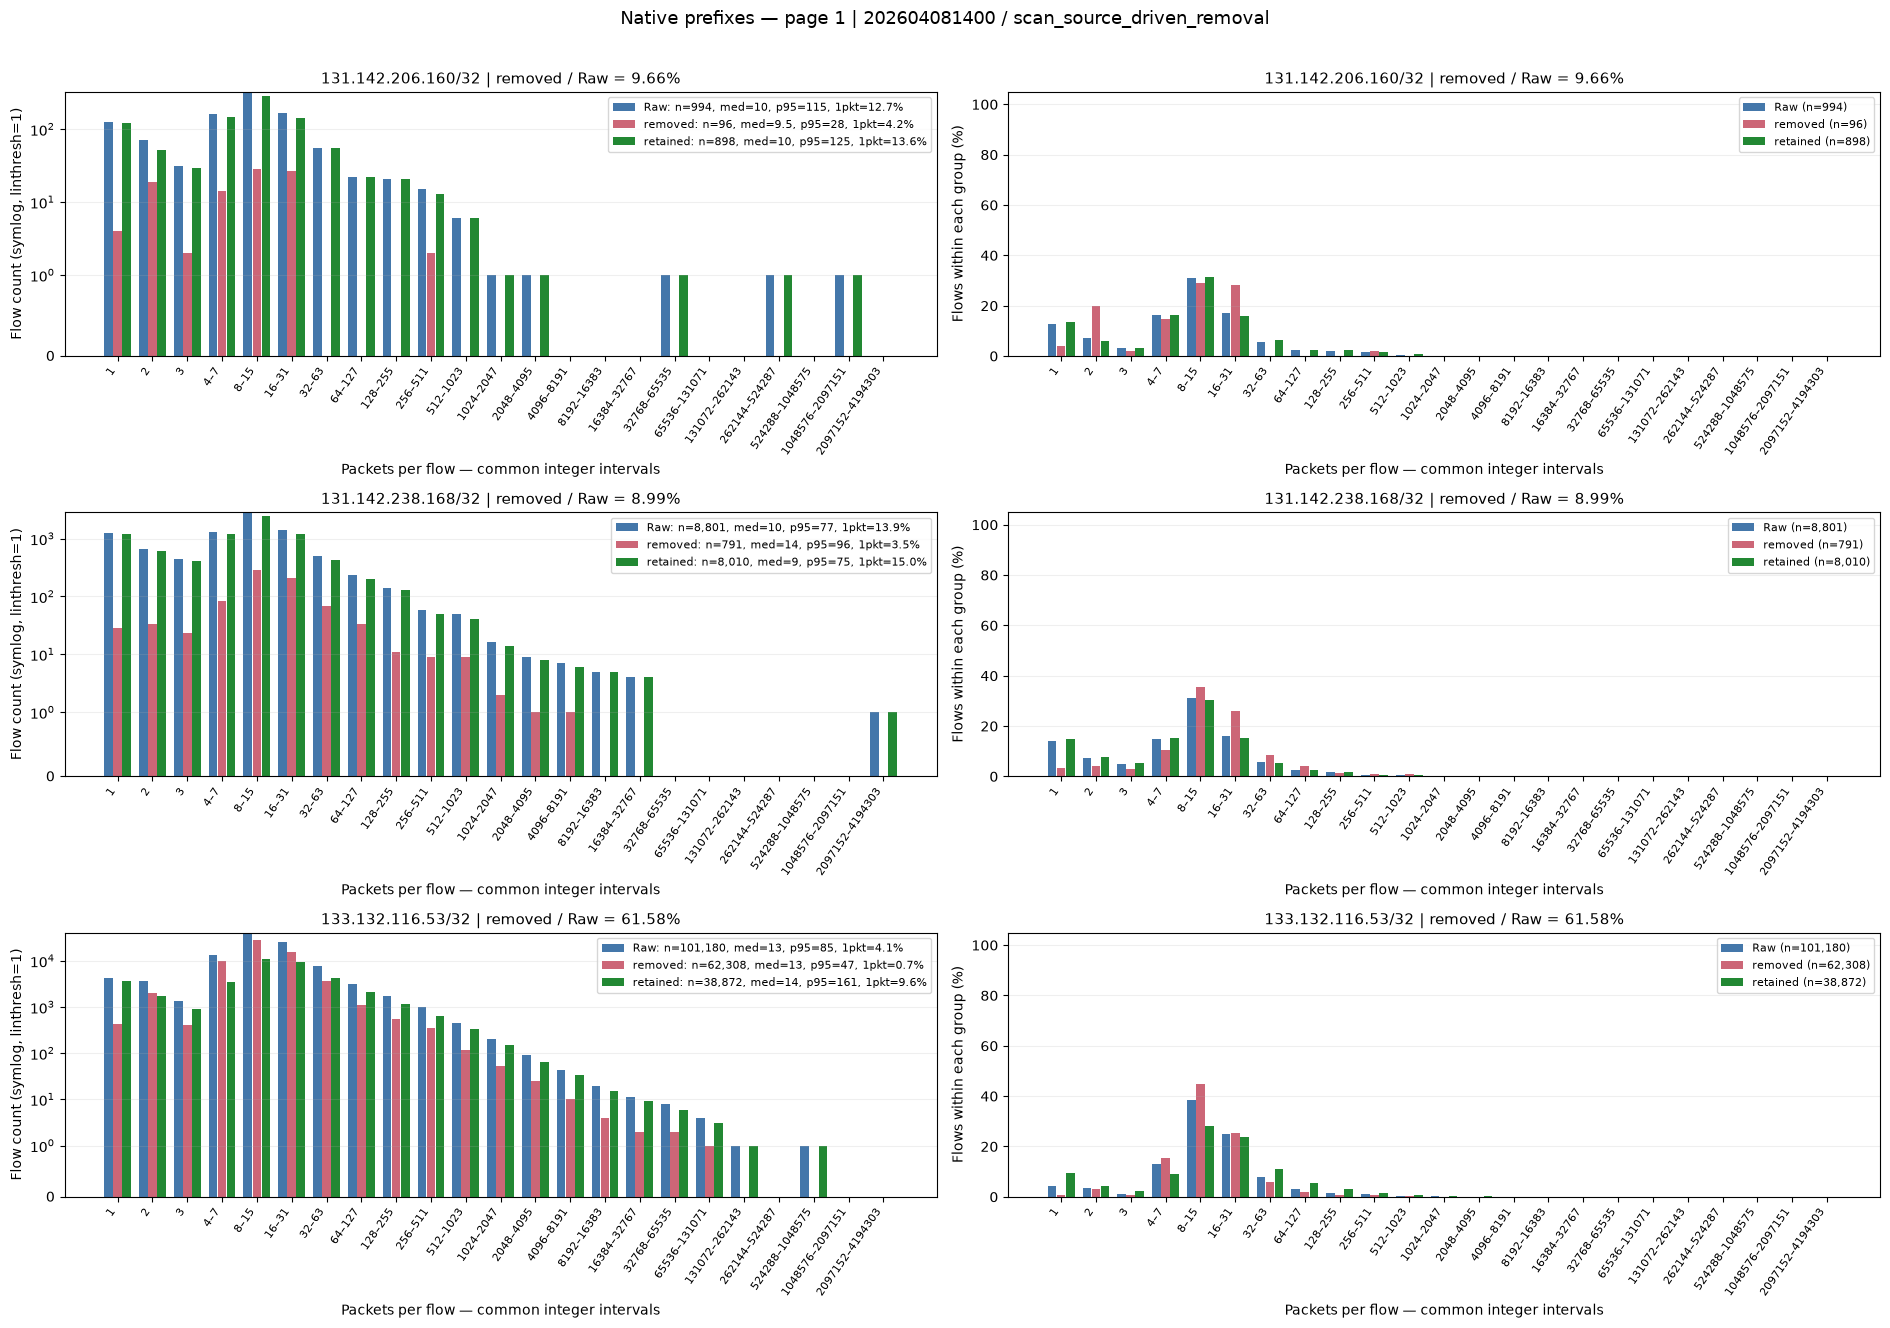

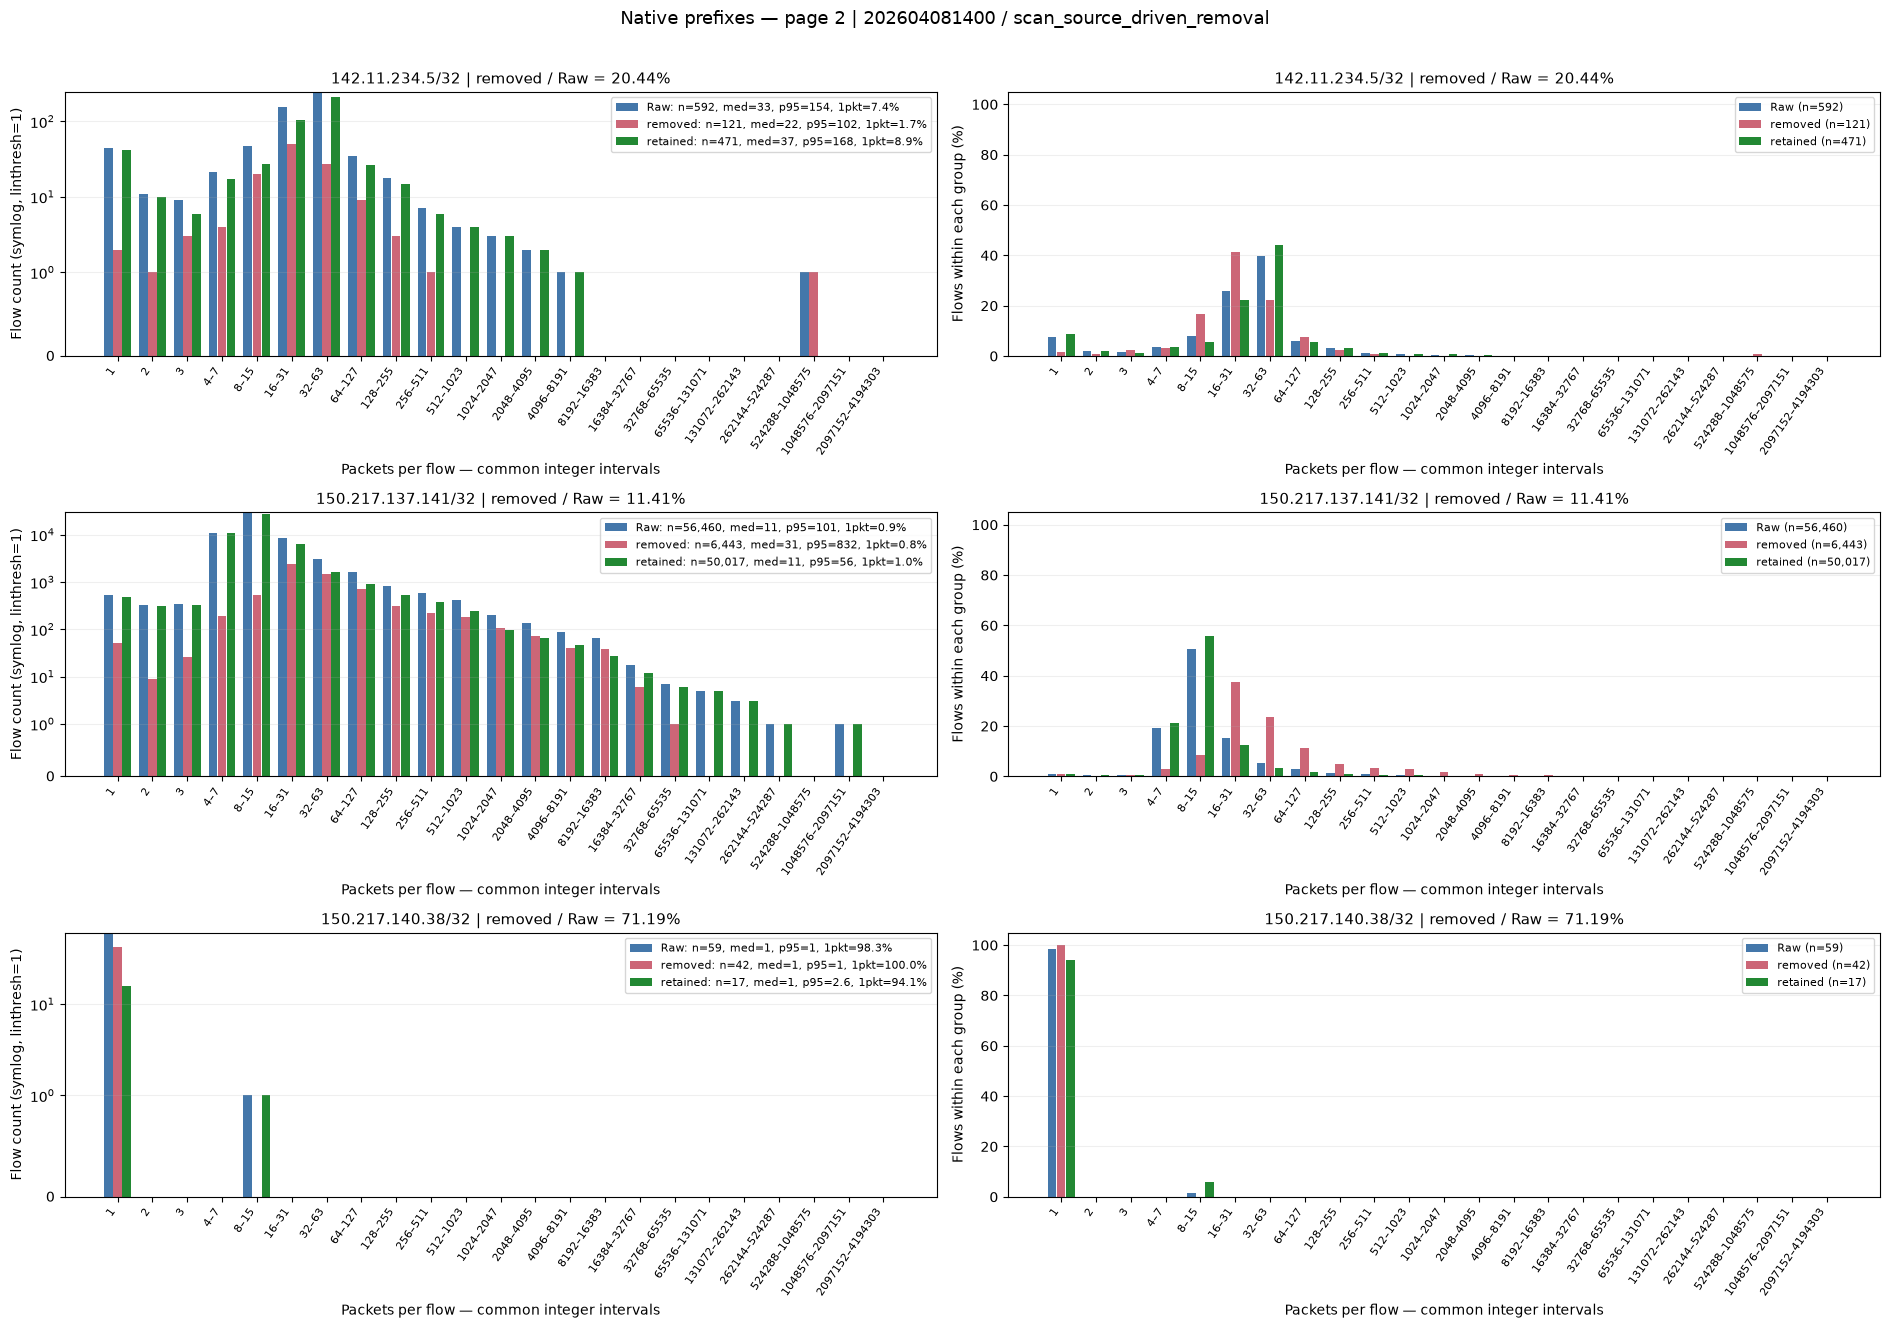

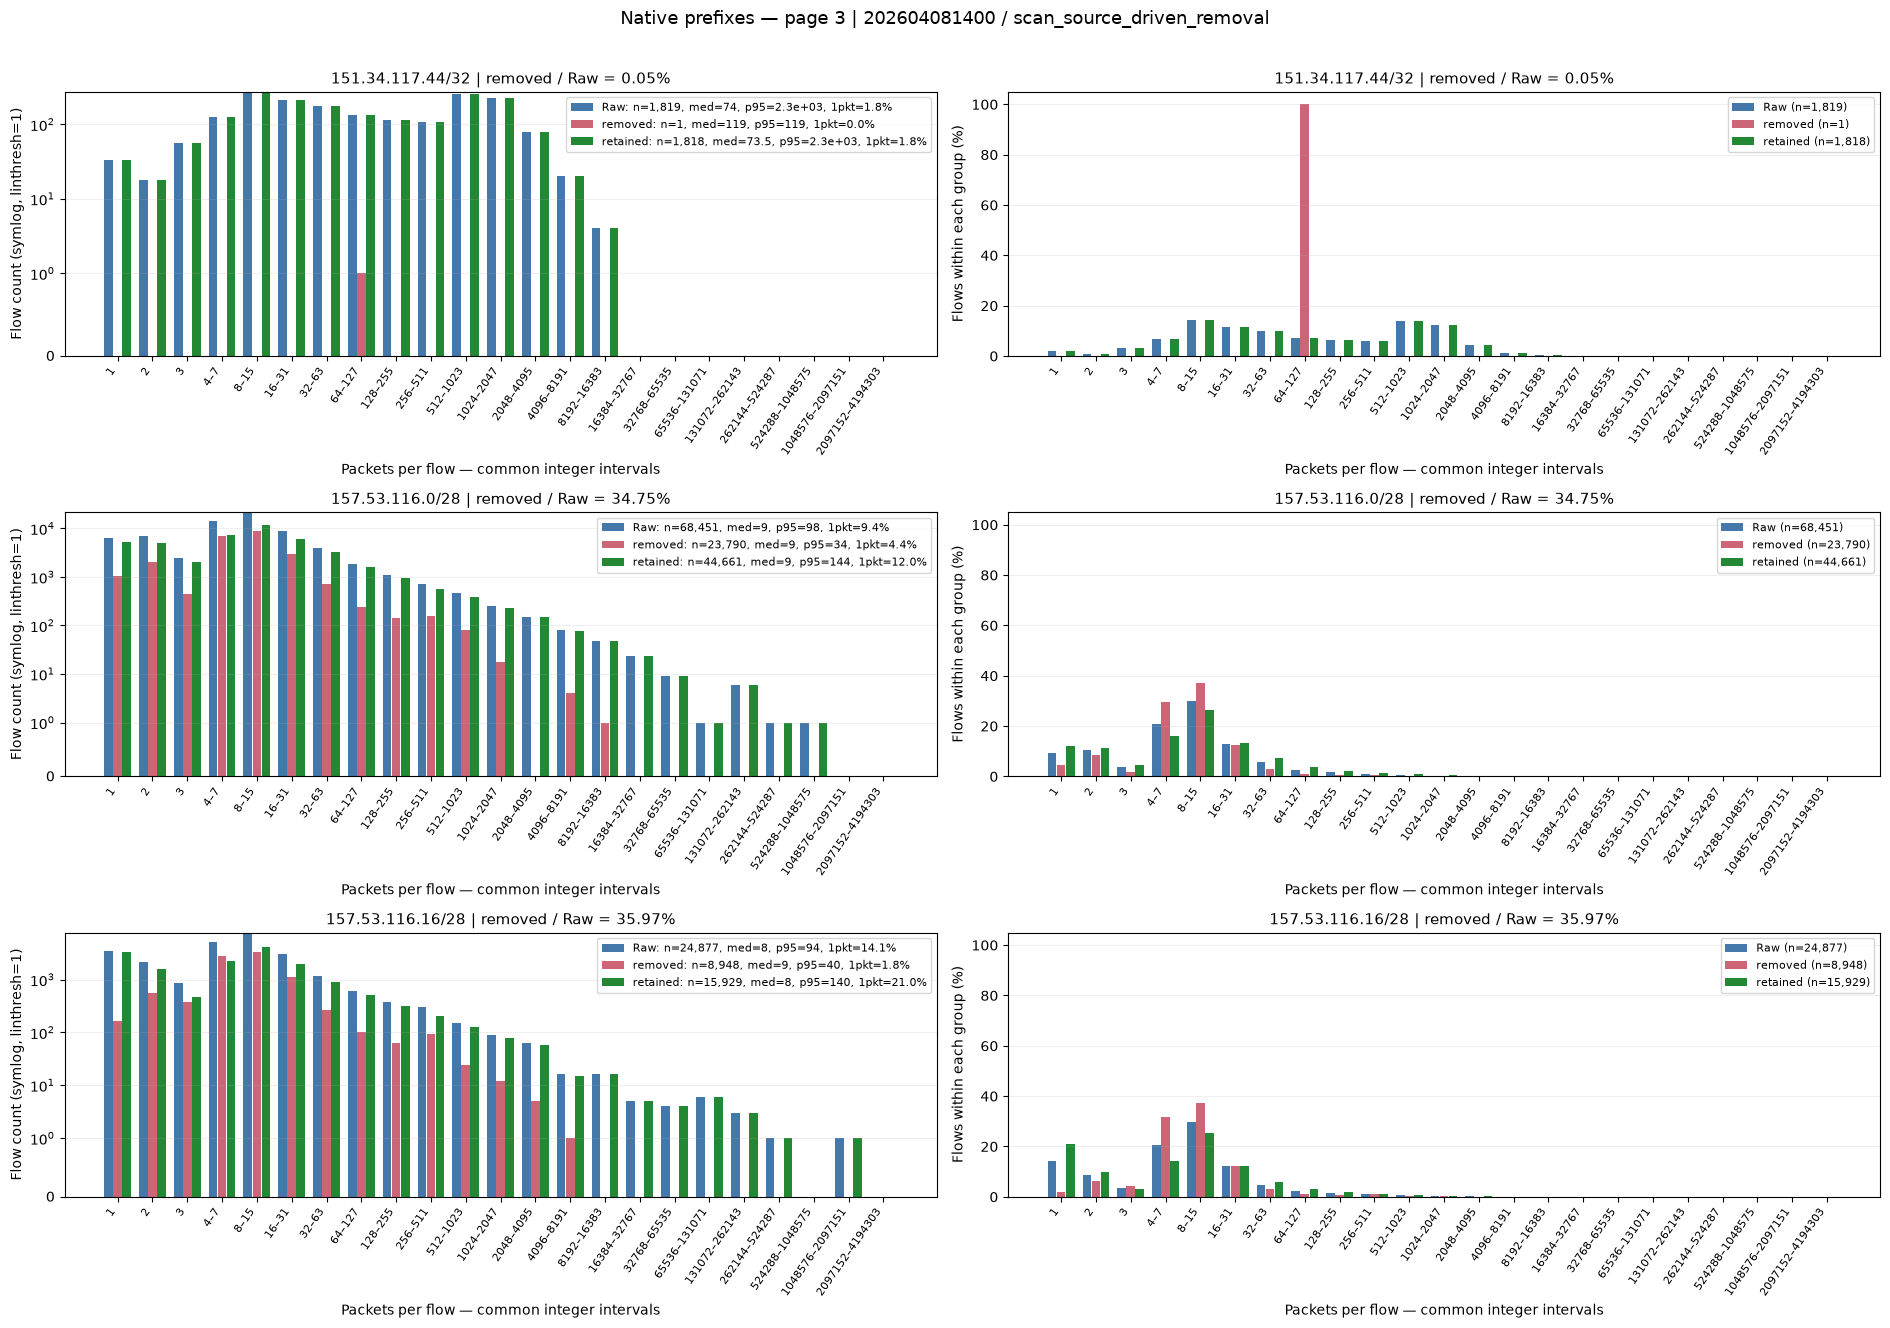

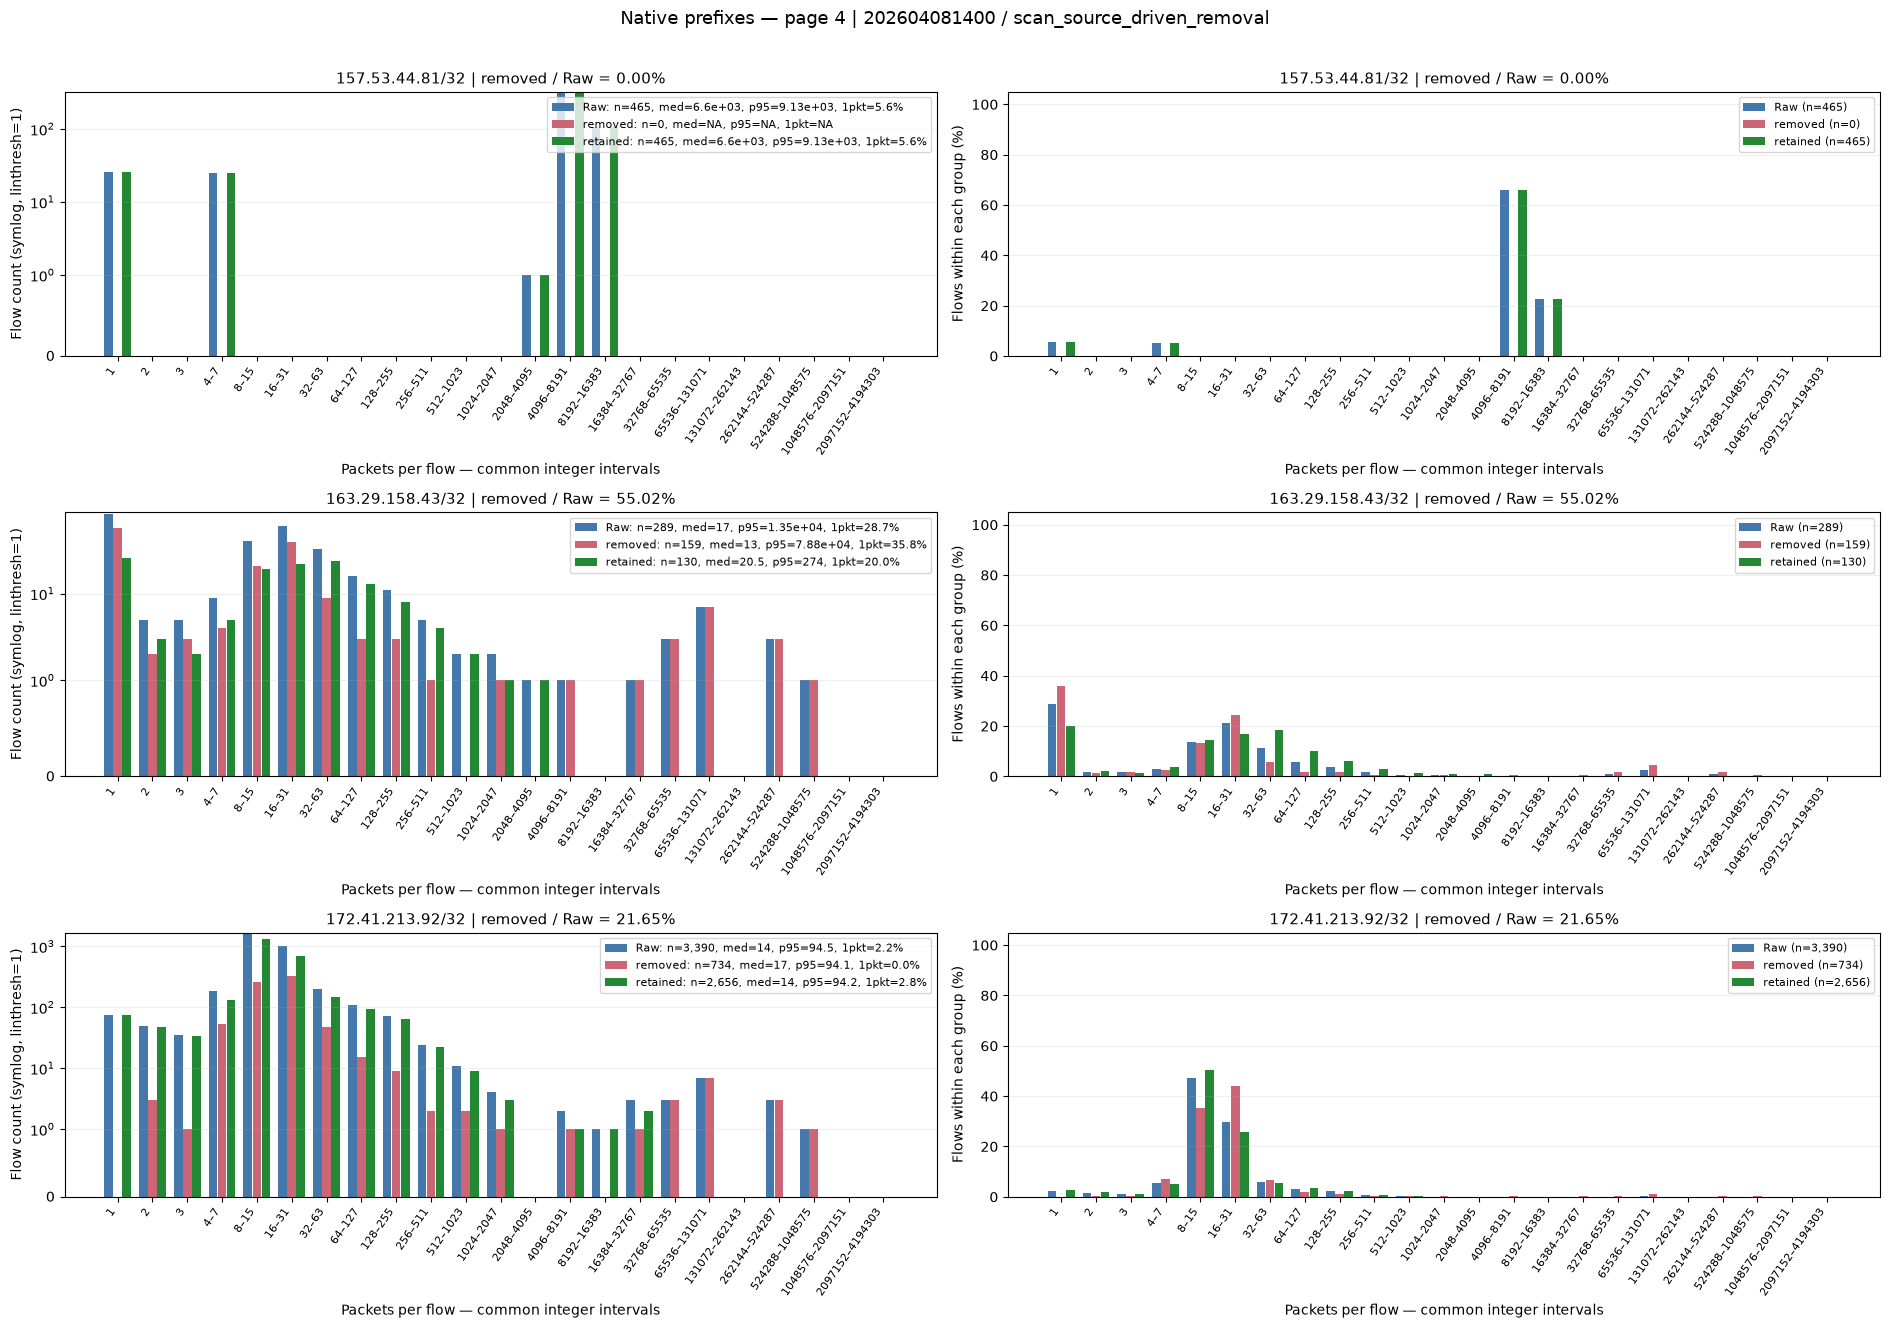

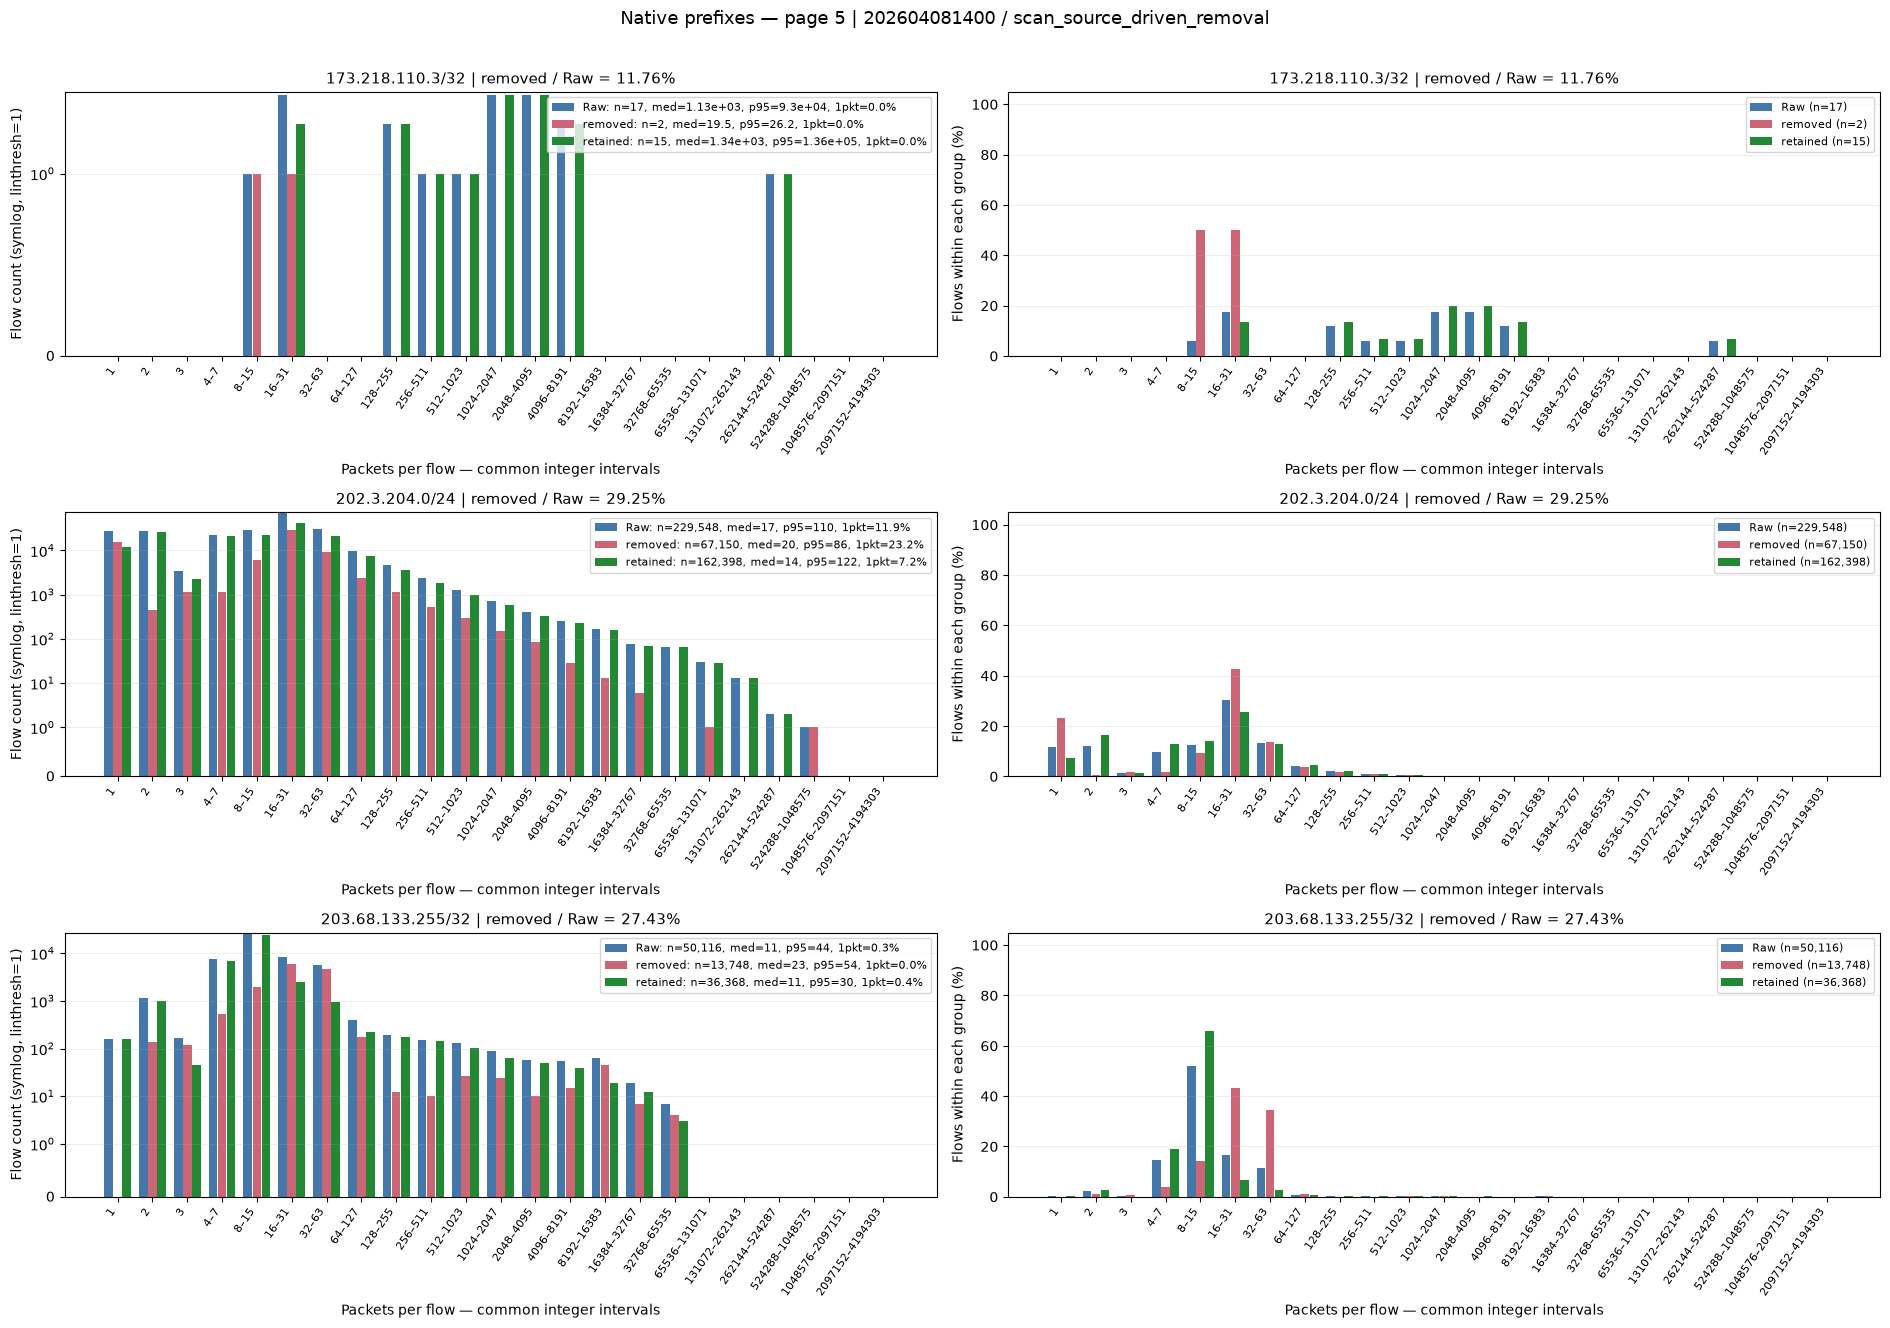

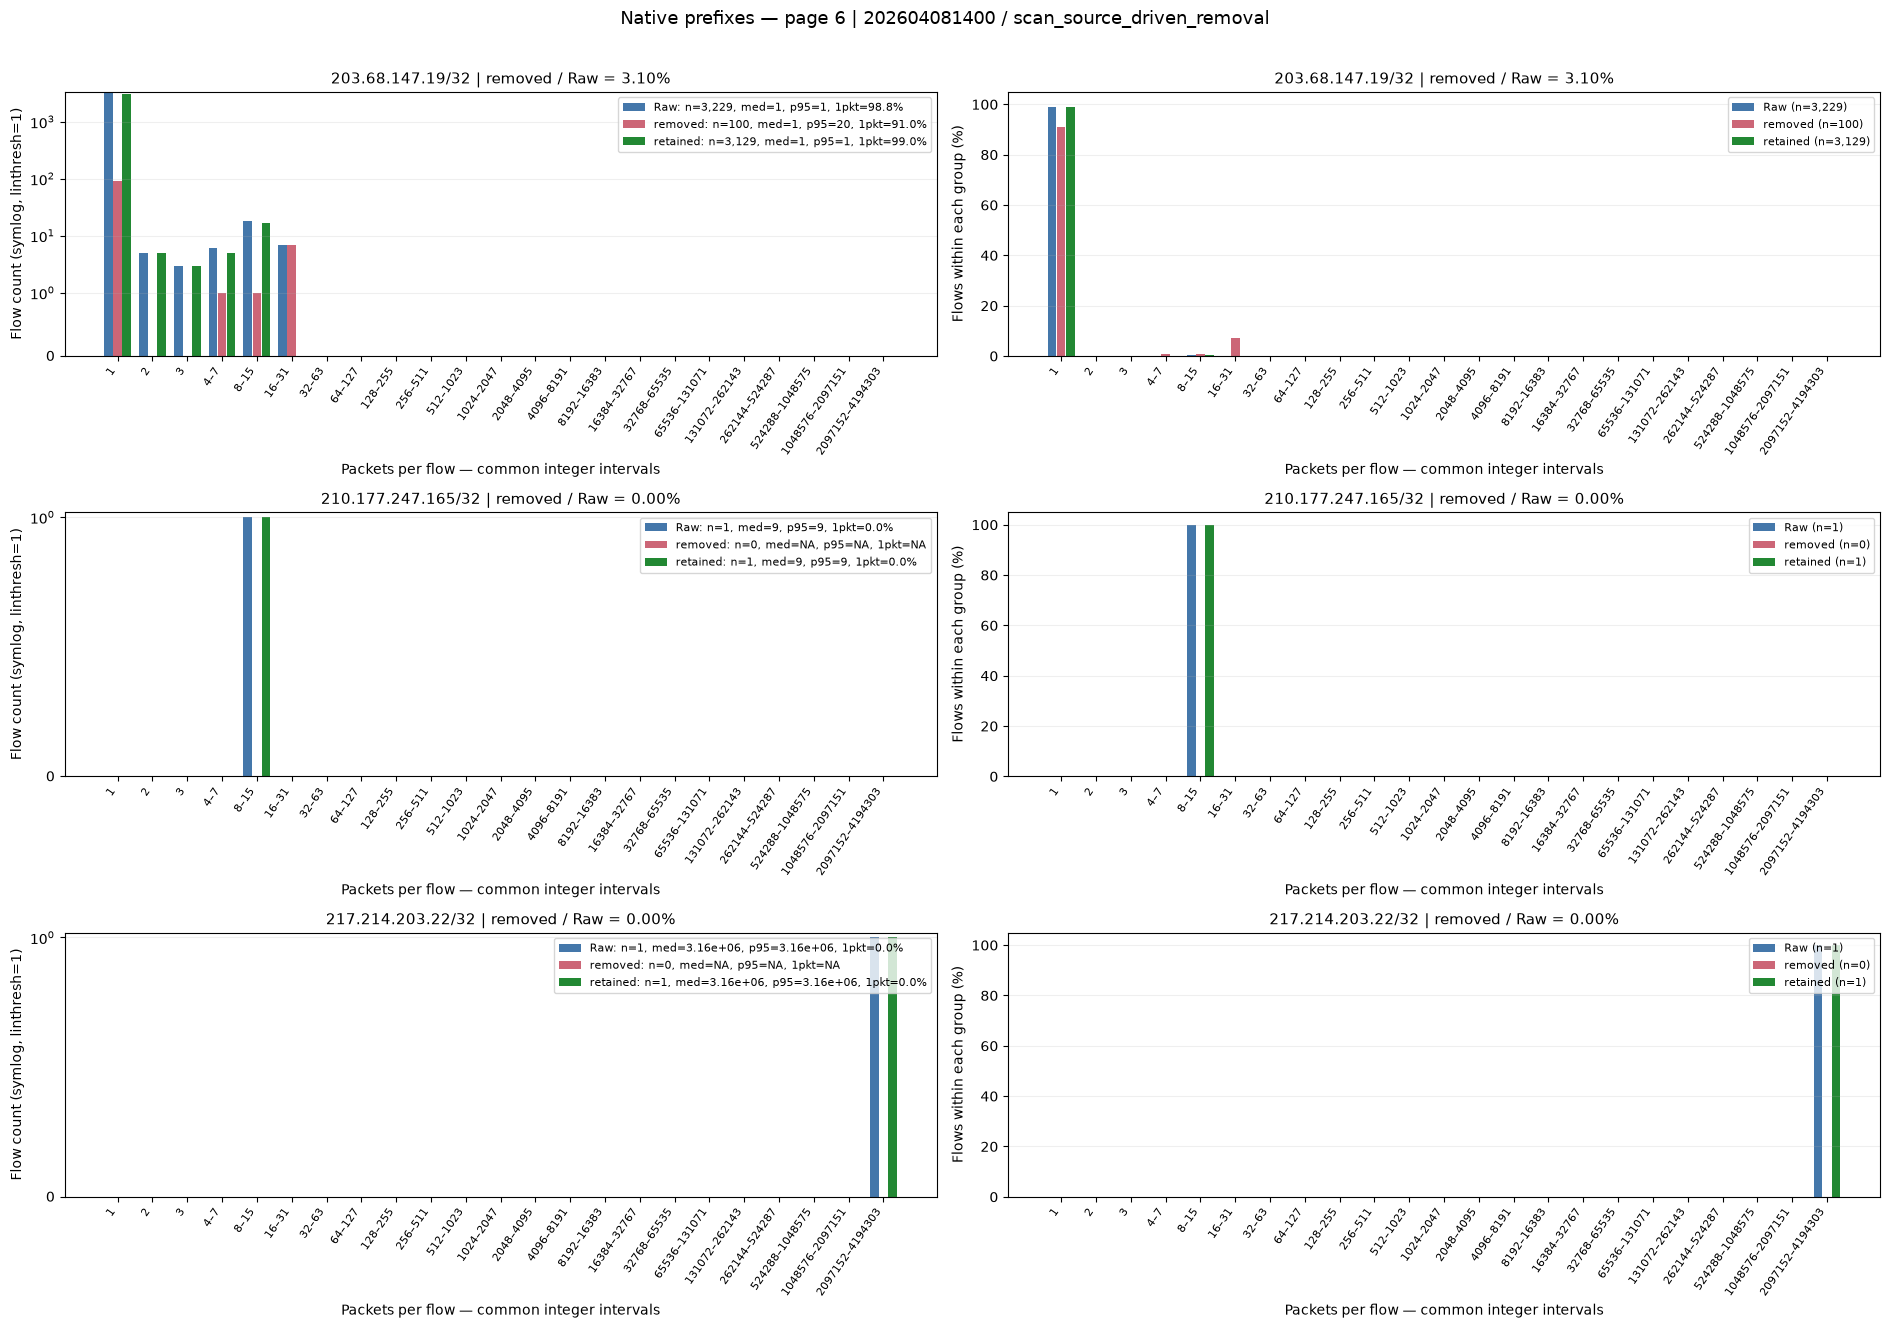

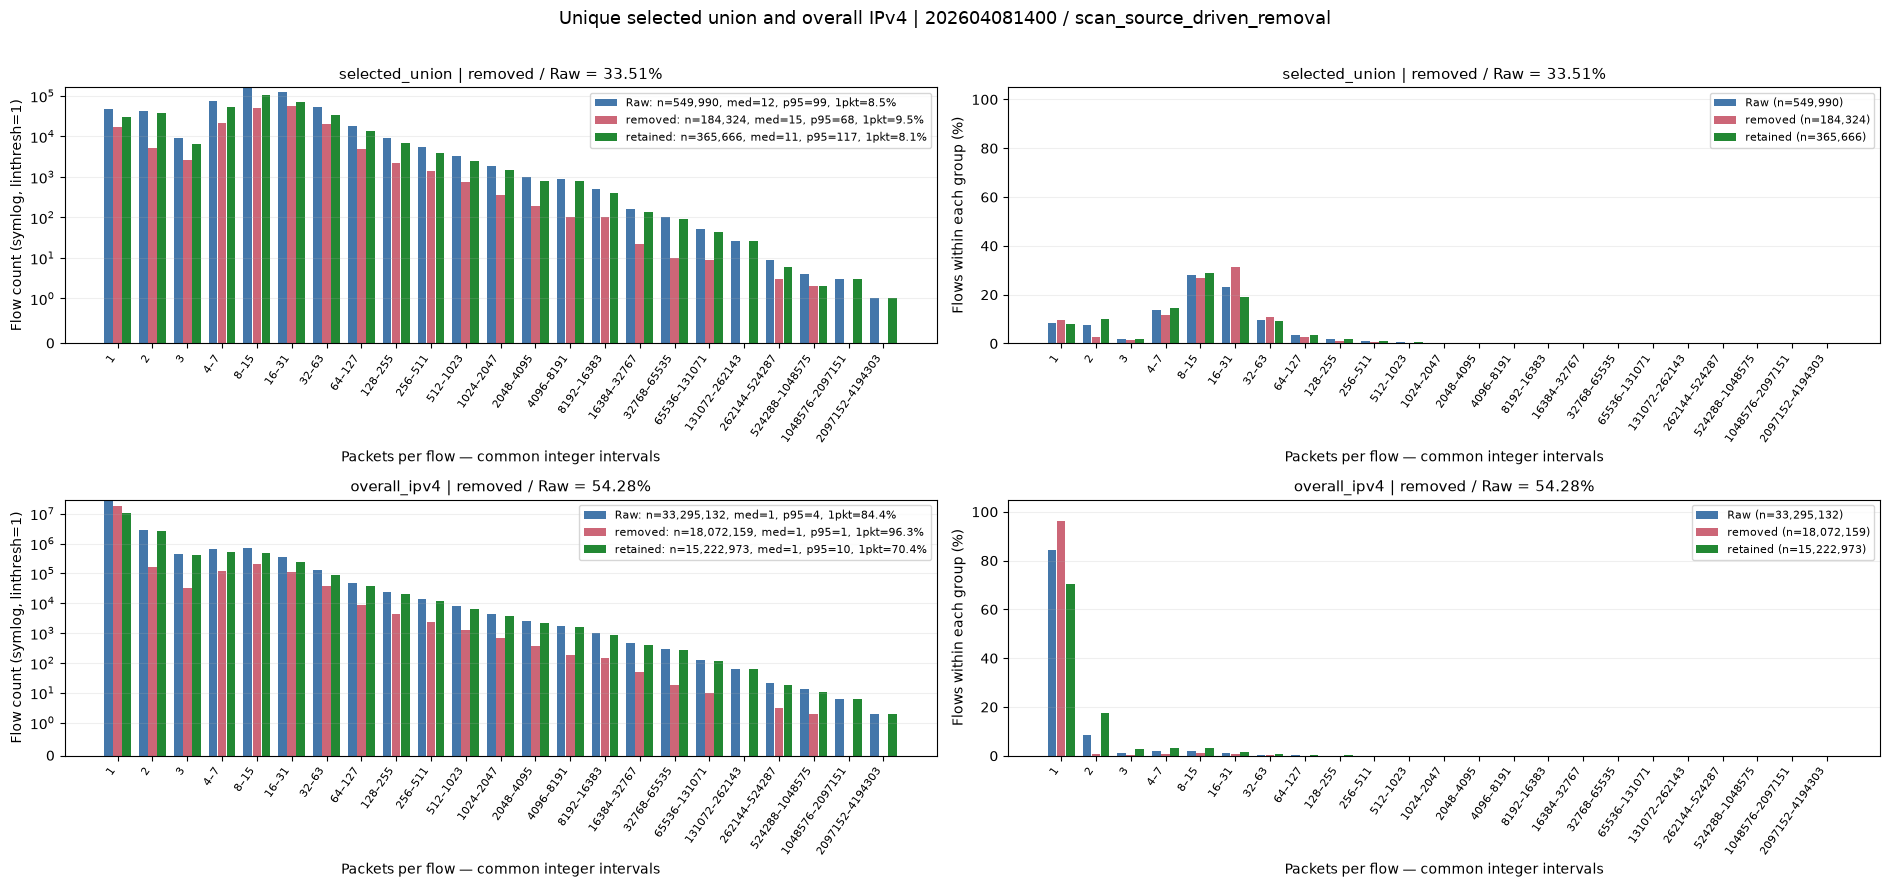

In [6]:
require_result()
bin_labels = [str(lo) if hi == lo + 1 else f'{lo}–{hi-1}'
              for lo, hi in zip(result.bin_edges, result.bin_edges[1:])]
display(pd.DataFrame({'lower (inclusive)': result.bin_edges[:-1],
                      'upper (exclusive)': result.bin_edges[1:], 'label': bin_labels}))
colors = {'Raw': '#4477AA', 'removed': '#CC6677', 'retained': '#228833'}
figures = []

def number(value):
    return 'NA' if pd.isna(value) else f'{value:,.3g}'

def plot_page(targets, title):
    fig, axes = plt.subplots(len(targets), 2, figsize=(19, 4.5 * len(targets)), squeeze=False)
    x = np.arange(len(bin_labels))
    for row, prefix in enumerate(targets):
        stats = summary.loc[summary.prefix.eq(prefix)].set_index('group')
        rate = stats.loc['Raw', 'removal_rate']
        rate_text = 'NA' if pd.isna(rate) else f'{rate:.2%}'
        for j, group in enumerate(('Raw', 'removed', 'retained')):
            frequency = histogram.loc[histogram.prefix.eq(prefix) & histogram.group.eq(group)]
            s = stats.loc[group]
            one_text = 'NA' if pd.isna(s.one_packet_rate) else f'{s.one_packet_rate:.1%}'
            legend = (f'{group}: n={int(s.flow_count):,}, med={number(s["median"])}, '
                      f'p95={number(s.p95)}, 1pkt={one_text}')
            axes[row, 0].bar(x + (j-1)*0.26, frequency.flow_count, width=0.25,
                             color=colors[group], label=legend)
            axes[row, 1].bar(x + (j-1)*0.26, frequency.proportion*100, width=0.25,
                             color=colors[group], label=f'{group} (n={int(s.flow_count):,})')
        for col, axis in enumerate(axes[row]):
            axis.set_title(f'{prefix} | removed / Raw = {rate_text}', fontsize=11)
            axis.set_xticks(x, bin_labels, rotation=55, ha='right', fontsize=8)
            axis.set_xlabel('Packets per flow — common integer intervals')
            axis.grid(axis='y', alpha=.2)
            axis.legend(fontsize=8, loc='upper right')
            if col == 0:
                axis.set_ylabel('Flow count' + (' (symlog, linthresh=1)' if COUNT_LOG else ''))
                if COUNT_LOG: axis.set_yscale('symlog', linthresh=1)
                axis.set_ylim(bottom=0, top=max(1, axis.get_ylim()[1]))
            else:
                axis.set_ylabel('Flows within each group (%)')
                axis.set_ylim(0, 105)
    fig.suptitle(title + (' | SYNTHETIC DEMO' if IS_SYNTHETIC else f' | {DATASET_ID} / {RUN_NAME}'), fontsize=13)
    fig.tight_layout(rect=(0, 0, 1, .97))
    figures.append(fig)
    display(fig)
    plt.close(fig)

for start in range(0, len(prefixes), PREFIXES_PER_PAGE):
    plot_page(prefixes[start:start+PREFIXES_PER_PAGE], f'Native prefixes — page {start//PREFIXES_PER_PAGE+1}')
plot_page(['selected_union', 'overall_ipv4'], 'Unique selected union and overall IPv4')


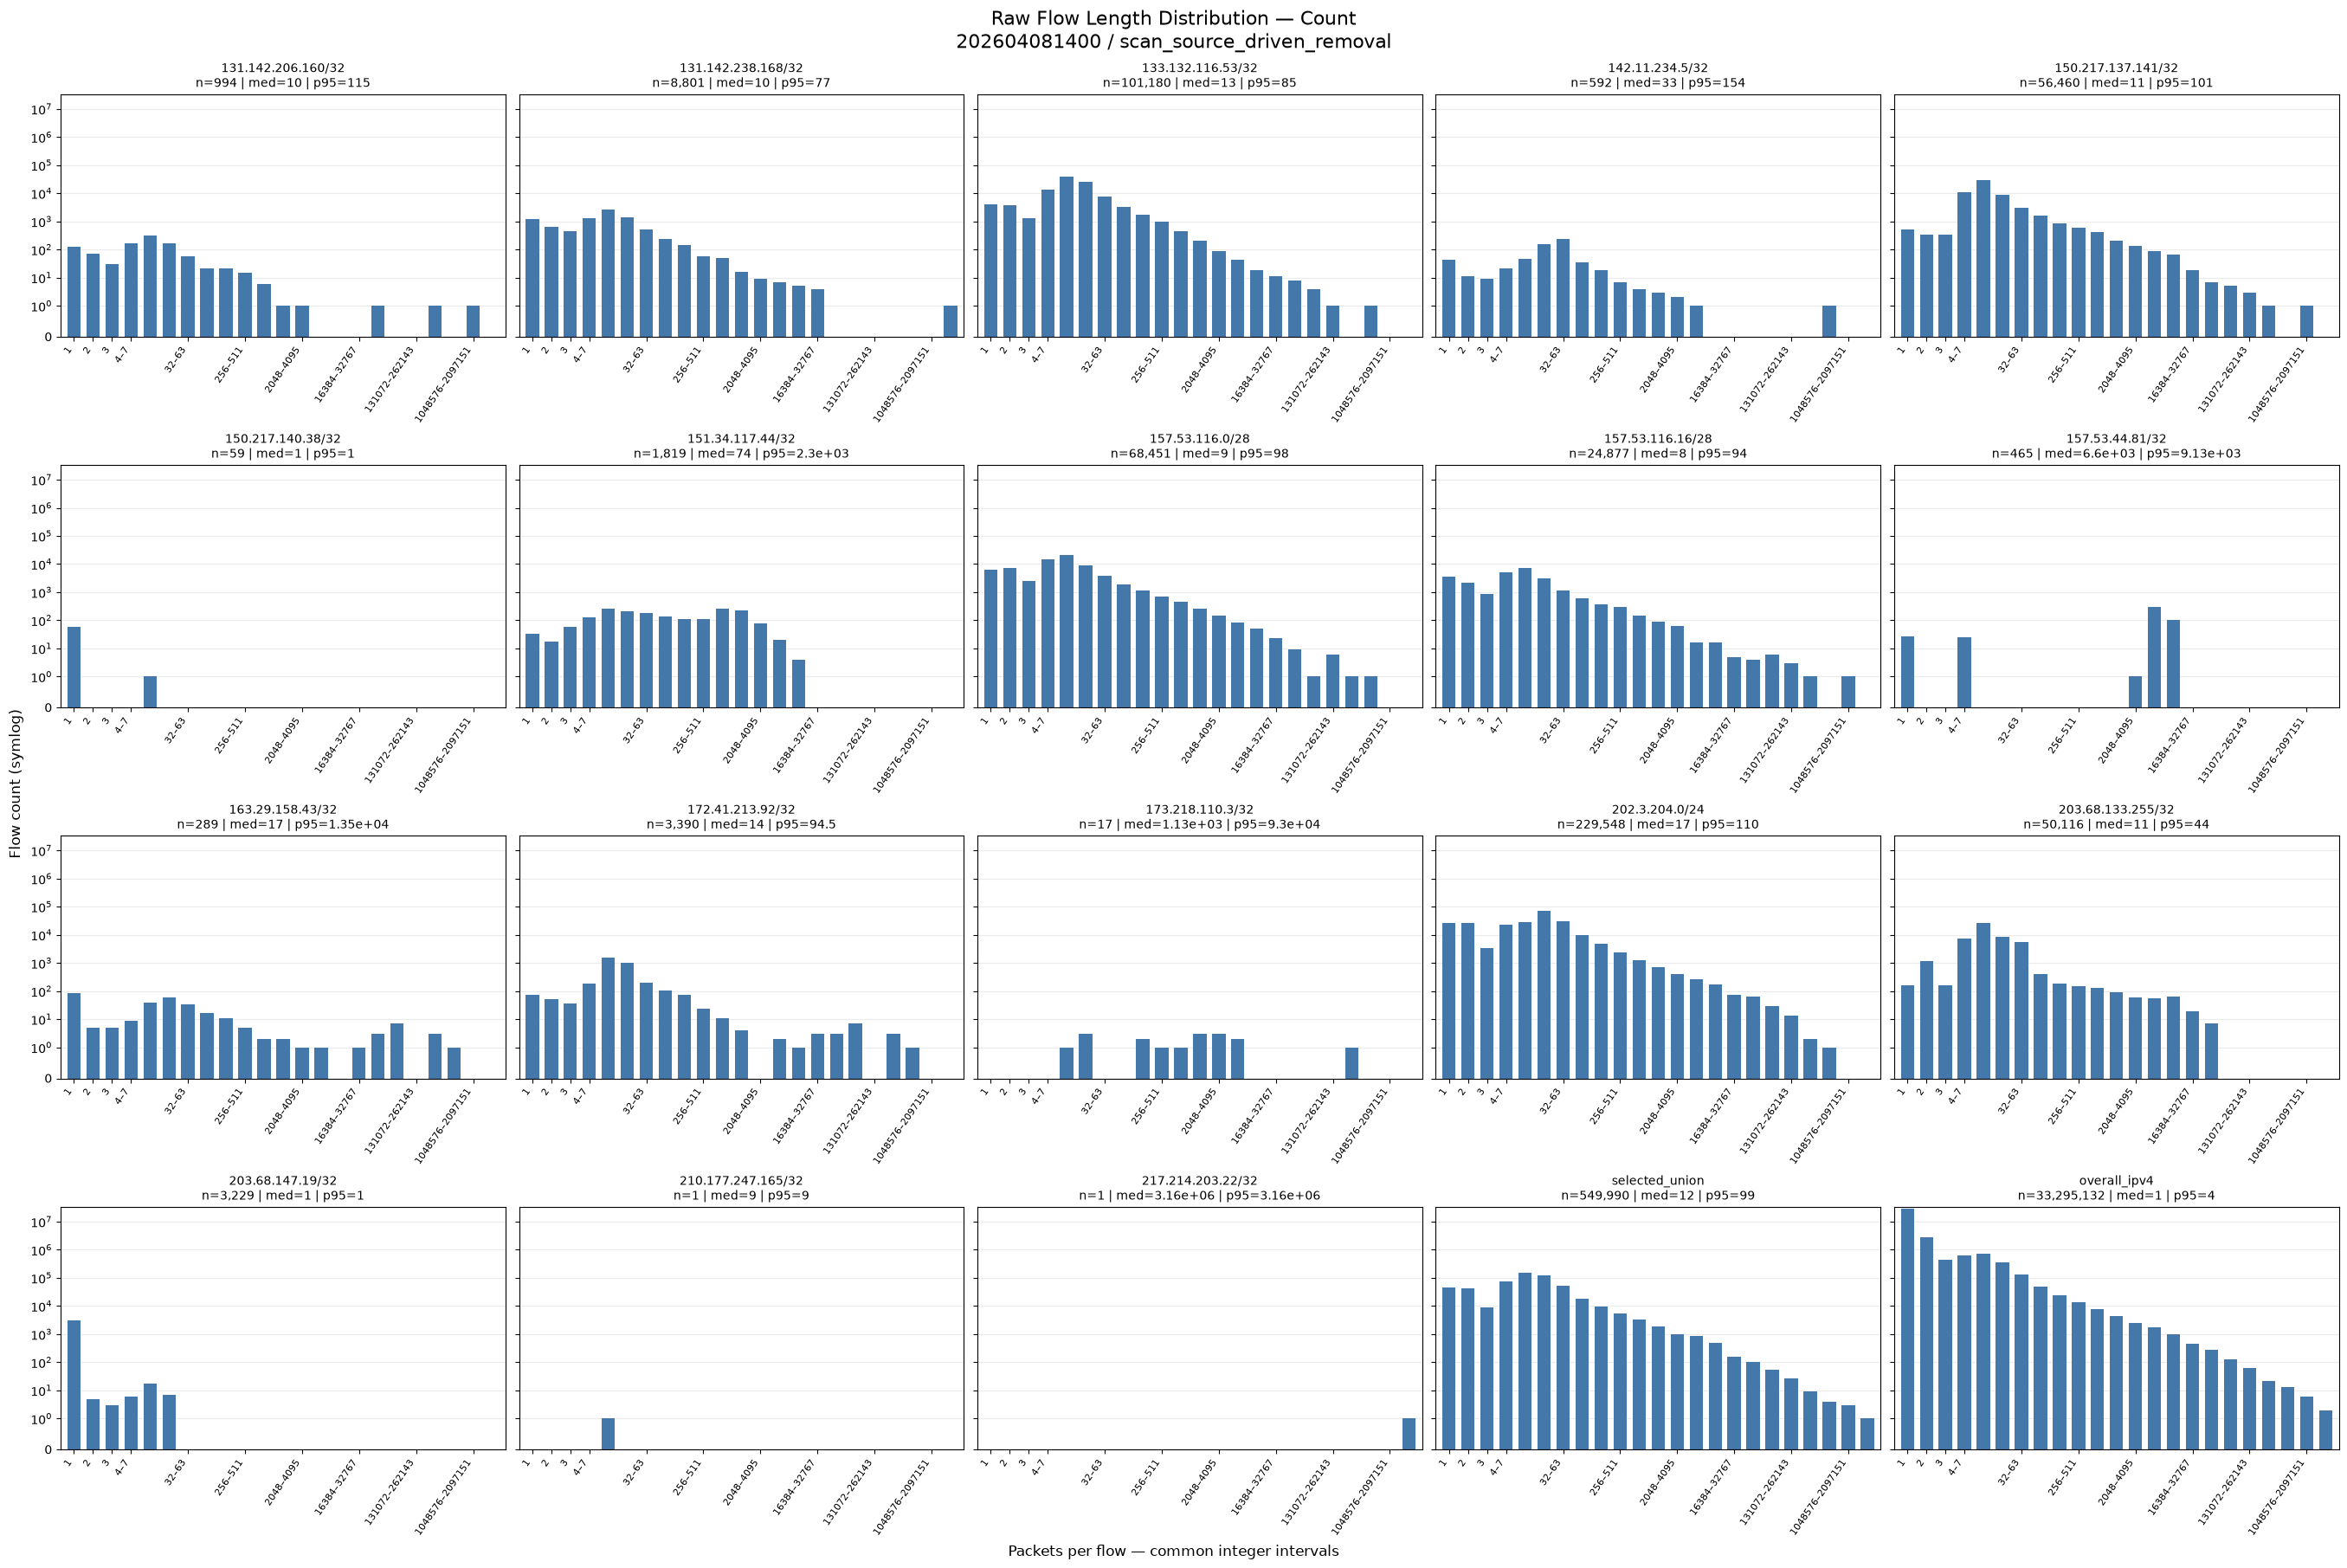

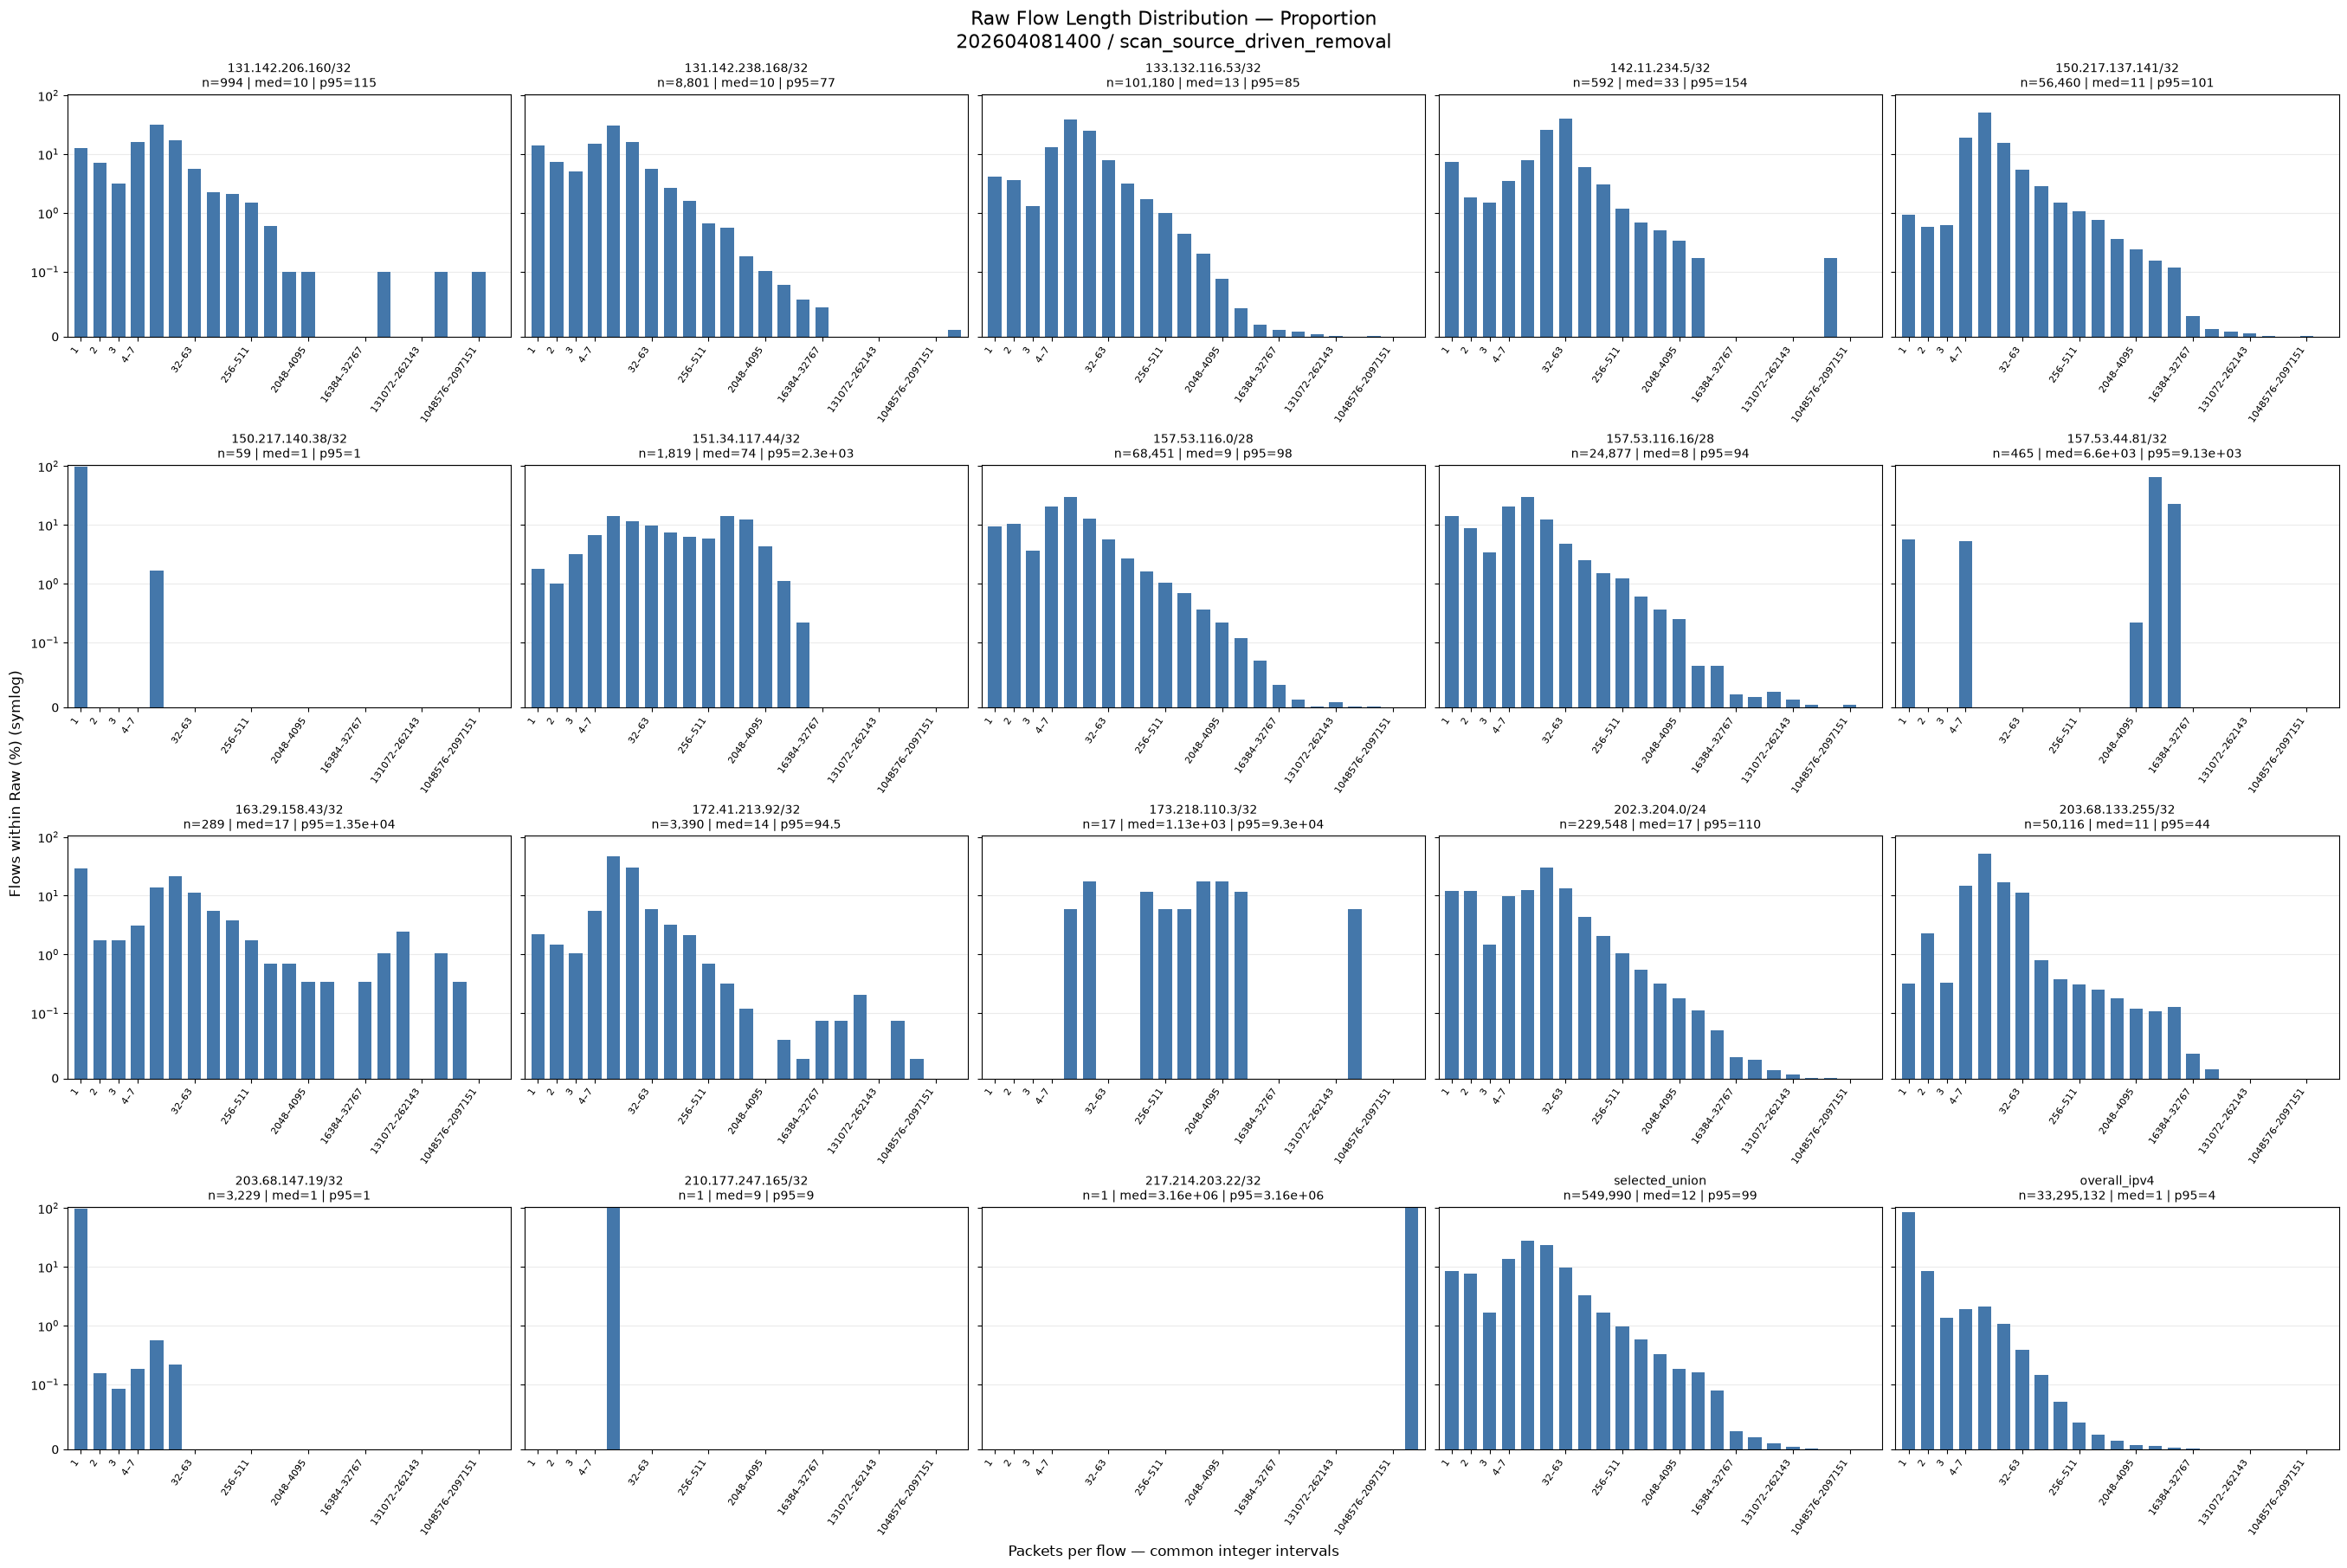

In [11]:
require_result()
GROUP_TO_PLOT = "Raw"
NROWS, NCOLS = 4, 5
COUNT_SCALE = "symlog"
PERCENT_SCALE = "symlog"
PERCENT_LINTHRESH = 0.1
COLOR = "#4477AA"
targets = list(prefixes) + ["selected_union", "overall_ipv4"]

if len(targets) > NROWS * NCOLS:
    raise ValueError(f"描画対象が{NROWS * NCOLS}件を超えています: {len(targets)}件")

bin_labels = [str(lo) if hi == lo + 1 else f"{lo}–{hi-1}" for lo, hi in zip(result.bin_edges[:-1], result.bin_edges[1:])]
x = np.arange(len(bin_labels))
tick_indices = [i for i in sorted(set([0, 1, 2] + list(range(3, len(bin_labels), 3)))) if i < len(bin_labels)]

raw_hist = histogram.loc[histogram.group.eq(GROUP_TO_PLOT)]
raw_summary = summary.loc[summary.group.eq(GROUP_TO_PLOT)].set_index("prefix")
COUNT_YMAX = max(1, float(raw_hist.flow_count.max()) * 1.2)
PERCENT_YMAX = 105

fig_count, axes_count = plt.subplots(NROWS, NCOLS, figsize=(27, 18), sharey=True, layout="constrained")
fig_percent, axes_percent = plt.subplots(NROWS, NCOLS, figsize=(27, 18), sharey=True, layout="constrained")
axes_count, axes_percent = axes_count.flatten(), axes_percent.flatten()

for ax in axes_count:
    if COUNT_SCALE == "symlog":
        ax.set_yscale("symlog", linthresh=1)
    else:
        ax.set_yscale("linear")

for ax in axes_percent:
    if PERCENT_SCALE == "symlog":
        ax.set_yscale("symlog", linthresh=PERCENT_LINTHRESH)
    else:
        ax.set_yscale("linear")

axes_count[0].set_ylim(0, COUNT_YMAX)
axes_percent[0].set_ylim(0, PERCENT_YMAX)

for i, prefix in enumerate(targets):
    frequency = raw_hist.loc[raw_hist.prefix.eq(prefix)]
    if len(frequency) != len(bin_labels):
        raise ValueError(f"{prefix}: ビン数が一致しません ({len(frequency)} != {len(bin_labels)})")

    s = raw_summary.loc[prefix]
    count_values = frequency.flow_count.to_numpy()
    percent_values = frequency.proportion.to_numpy() * 100
    title = f'{prefix}\nn={int(s.flow_count):,} | med={s["median"]:,.3g} | p95={s.p95:,.3g}'

    for ax, values in ((axes_count[i], count_values), (axes_percent[i], percent_values)):
        ax.bar(x, values, width=0.7, color=COLOR)
        ax.set_title(title, fontsize=10)
        ax.set_xticks(tick_indices, [bin_labels[j] for j in tick_indices], rotation=55, ha="right", fontsize=8)
        ax.set_xlim(-0.7, len(bin_labels) - 0.3)
        ax.grid(axis="y", alpha=0.25)
        ax.set_axisbelow(True)

for i in range(len(targets), NROWS * NCOLS):
    axes_count[i].set_visible(False)
    axes_percent[i].set_visible(False)

fig_count.suptitle(f"Raw Flow Length Distribution — Count\n{DATASET_ID} / {RUN_NAME}", fontsize=16)
fig_count.supxlabel("Packets per flow — common integer intervals", fontsize=12)
fig_count.supylabel(f"Flow count ({COUNT_SCALE})", fontsize=12)

fig_percent.suptitle(f"Raw Flow Length Distribution — Proportion\n{DATASET_ID} / {RUN_NAME}", fontsize=16)
fig_percent.supxlabel("Packets per flow — common integer intervals", fontsize=12)
fig_percent.supylabel(f"Flows within Raw (%) ({PERCENT_SCALE})", fontsize=12)

display(fig_count)
display(fig_percent)

figures = [fig_count, fig_percent]
plt.close(fig_count)
plt.close(fig_percent)